# 09 - Traitement NLP des avis (sentiment TF-IDF / n-grammes) et recommandation hybride

Retour d'évaluation : **intégrer une analyse de sentiment TF-IDF / n-grammes sur le texte des avis, combinée aux attributs tabulaires (taille, âge, note)**, puis proposer un **système de recommandation hybride** avec score de confiance probabiliste calibré (interface : page « Recommandation Hybride » de `src/app.py`).

| Étape | Contenu |
|---|---|
| 1 | Extraction des attributs de **taille** depuis le texte (le dataset n'a pas de colonne taille) |
| 2 | **Ablation hermétique** : tabulaire / + tailles / + sentiment / hybride complet / référence TF-IDF direct, avec et sans `Rating` |
| 3 | Interprétation du sentiment (termes les plus positifs / négatifs) |
| 4 | **Recommandeur hybride calibré** (profil + texte), évalué sur des produits jamais vus |

Les classes `SizeFeatures` et `OOFSentimentScorer` et les fonctions du recommandeur sont dans `src/ml_utils.py` (le fichier `.pkl` doit pouvoir être rechargé par l'application).

In [3]:
import os, sys, time, warnings
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
from ml_utils import (CATEGORICAL, NUMERIC, RANDOM_STATE, build_preprocessor, ece, evaluate_scores, get_cv, load_clean_data,
                      split_data, OOFSentimentScorer, SizeFeatures, SIZE_FEATURE_NAMES, size_frame, join_text,
                      FEATURES, RECO_PATH, NLP_PIPE_PATH, product_arrays, profile_features)

FAST_MODE = os.environ.get("DM_FAST", "0") == "1"
SUB = "fast" if FAST_MODE else ""
FIG_DIR = ROOT / "docs" / "figures" / SUB; REPORT_DIR = ROOT / "reports" / SUB
FIG_DIR.mkdir(parents=True, exist_ok=True); REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean_data()
if FAST_MODE:
    df = df.sample(5000, random_state=RANDOM_STATE)
X_train, X_test, y_train, y_test = split_data(df)
cv = get_cv()
print(df.shape, X_train.shape, X_test.shape)

(23465, 10) (18772, 8) (4693, 8)


## 1. L'attribut « taille » est extrait du texte

Le dataset ne contient ni la taille de la cliente ni la taille portée. Des expressions régulières sur `Title` + `Review Text` extraient :
la taille en cm (pieds/pouces convertis), la taille portée (XS à XXL ou numérique), « tombe petit », « tombe grand » et « true to size ».
Quand l'information est absente, la valeur reste `NaN` et c'est l'`SimpleImputer` du pipeline (avec indicateur de manquant) qui s'en charge.

In [4]:
sz = size_frame(df)
cover = pd.DataFrame({"% renseigné": sz.notna().mean().round(3), "moyenne": sz.mean().round(2)}).loc[SIZE_FEATURE_NAMES]
display(cover)

,% renseigné,moyenne
height_cm,0.192,164.84
size_ord,0.131,1.84
size_num,0.065,6.01
petite,1.000,0.08
runs_small,1.000,0.08
runs_large,1.000,0.11
true_to_size,1.000,0.12


## 2. Ablation hermétique : tabulaire, tailles, sentiment

Chaque variante est **un seul `Pipeline`** passé à `cross_validate` : imputation, standardisation, one-hot, extraction de taille et score de sentiment sont réappris sur le train de chaque pli.
Le score de sentiment (TF-IDF 1-3 grammes + régression logistique, polarité `Rating >= 4`) est calculé **hors-pli** à l'intérieur de `OOFSentimentScorer.fit_transform` : le modèle final ne voit donc jamais un score « en échantillon » trop optimiste.
Classifieur identique partout (régression logistique) pour isoler l'effet des variables.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def tabular_block(drop=()):
    num = [c for c in NUMERIC if c not in drop]
    return [("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
            ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("oh", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL)]

size_block = ("size", Pipeline([("ext", SizeFeatures()), ("imp", SimpleImputer(strategy="median", add_indicator=True)),
                                ("sc", StandardScaler())]), ["Title", "Review Text"])

sentiment_block = ("sentiment", OOFSentimentScorer(), ["Title", "Review Text", "Rating"])

def make_variant(code):
    drop = ("Rating",) if code.endswith("'") else ()
    kind = code[0]
    if kind == "A": pre = ColumnTransformer(tabular_block(drop))
    elif kind == "B": pre = ColumnTransformer(tabular_block(drop) + [size_block])
    elif kind == "C": pre = ColumnTransformer(tabular_block(drop) + [sentiment_block])
    elif kind == "D": pre = ColumnTransformer(tabular_block(drop) + [size_block, sentiment_block])
    else: pre = build_preprocessor(drop_columns=drop)          # E : TF-IDF direct (prétraitement du notebook 02)
    return Pipeline([("pre", pre), ("clf", LogisticRegression(C=0.5, max_iter=3000))])

VARIANTS = {"A": "A. Tabulaire seul", "B": "B. Tabulaire + tailles extraites", "C": "C. Tabulaire + sentiment (TF-IDF 1-3 grammes)",
            "D": "D. Hybride complet (tabulaire + tailles + sentiment)", "E": "E. Référence : tabulaire + TF-IDF direct",
            "A'": "A'. Tabulaire seul, sans Rating", "D'": "D'. Hybride complet, sans Rating", "E'": "E'. Référence TF-IDF direct, sans Rating"}

In [6]:
rows, probas, fitted = [], {}, {}
for code, name in VARIANTS.items():
    t0 = time.time()
    pipe = make_variant(code)
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)["test_score"]
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    m = evaluate_scores(y_test, (p >= 0.5).astype(int), p)
    rows.append({"Variante": name, "CV F1 macro (moy.)": scores.mean(), "CV F1 macro (écart-type)": scores.std(),
                 "F1 macro (test)": m["F1 macro"], "F1 (0)": m["F1 (0)"], "ROC-AUC": m["ROC-AUC"], "PR-AUC": m["PR-AUC"],
                 "Brier": float(np.mean((p - y_test.to_numpy()) ** 2)), "ECE": ece(y_test.to_numpy(), p), "Temps CV (s)": time.time() - t0})
    fitted[code], probas[code] = pipe, p
res = pd.DataFrame(rows)
res.to_csv(REPORT_DIR / "nlp_hybrid_results.csv", index=False)
display(res.round(4))

,Variante,CV F1 macro (moy.),CV F1 macro (écart-type),F1 macro (test),F1 (0),ROC-AUC,PR-AUC,Brier,ECE,Temps CV (s)
0,A. Tabulaire seul,0.8959,0.0056,0.8859,0.8152,0.9716,0.9933,0.0446,0.0081,8.2347
1,B. Tabulaire + tailles extraites,0.8968,0.0047,0.8872,0.8161,0.9731,0.9937,0.0440,0.0078,7.6258
2,C. Tabulaire + sentiment (TF-IDF 1-3 grammes),0.9072,0.0035,0.8985,0.8333,0.9793,0.9944,0.0406,0.0085,161.0092
3,D. Hybride complet (tabulaire + tailles + sent...,0.9072,0.0045,0.9028,0.8403,0.9796,0.9945,0.0401,0.0100,140.7026
4,E. Référence : tabulaire + TF-IDF direct,0.9065,0.0068,0.8958,0.8283,0.9775,0.9941,0.0414,0.0099,7.5076
5,"A'. Tabulaire seul, sans Rating",0.4521,0.0014,0.4522,0.0024,0.5503,0.8482,0.1457,0.0081,0.4976
6,"D'. Hybride complet, sans Rating",0.8386,0.0075,0.8403,0.7352,0.9497,0.9876,0.0654,0.0190,112.9351
7,"E'. Référence TF-IDF direct, sans Rating",0.7864,0.0140,0.7886,0.6380,0.9365,0.9838,0.0745,0.0522,7.8380


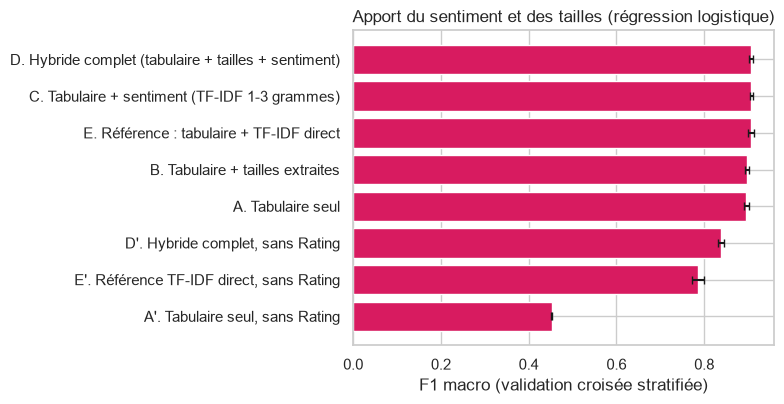

,bin,n,proba_moyenne,taux_observé
0,0.0-0.1,453,0.026,0.042
1,0.1-0.2,105,0.149,0.143
2,0.2-0.3,106,0.254,0.330
3,0.3-0.4,96,0.349,0.375
4,0.4-0.5,84,0.449,0.405
5,0.5-0.6,82,0.550,0.512
6,0.6-0.7,84,0.649,0.714
7,0.7-0.8,56,0.754,0.625
8,0.8-0.9,96,0.861,0.802
9,0.9-1.0,3531,0.992,0.993


In [ ]:
order = res.sort_values("CV F1 macro (moy.)")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(order["Variante"], order["CV F1 macro (moy.)"], xerr=order["CV F1 macro (écart-type)"], color="#D81B60", capsize=3)
ax.set_xlabel("F1 macro (validation croisée stratifiée)"); ax.set_title("Apport du sentiment et des tailles (régression logistique)")
fig.tight_layout(); fig.savefig(FIG_DIR / "nlp_hybrid_ablation.png", dpi=200); plt.show()


p, yt = probas["D"], y_test.to_numpy()
bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(p, bins[1:-1]), 0, 9)
calib = pd.DataFrame([{"bin": f"{bins[b]:.1f}-{bins[b+1]:.1f}", "n": int((idx == b).sum()), "proba_moyenne": float(p[idx == b].mean()),
                       "taux_observé": float(yt[idx == b].mean())} for b in range(10) if (idx == b).any()])
calib.to_csv(REPORT_DIR / "nlp_hybrid_calibration.csv", index=False)
display(calib.round(3))
if not FAST_MODE:
    joblib.dump(fitted["D"], NLP_PIPE_PATH)      

## 3. Interprétation du sentiment

Les coefficients de la régression logistique sur les n-grammes indiquent les termes qui font basculer un avis vers le positif ou le négatif.

In [8]:
scorer = fitted["D"].named_steps["pre"].named_transformers_["sentiment"]
pos, neg = scorer.top_terms(15)
print("Termes les plus positifs :", ", ".join(pos))
print("Termes les plus négatifs :", ", ".join(neg))
for t in ["Love it, perfect fit and so soft", "Cheap fabric, returned it, way too tight", "It is ok, nothing special"]:
    print(f"{scorer.score_texts([t])[0]:.2f}  {t}")

Termes les plus positifs : love, great, perfect, comfortable, love this, little, soft, not too, flattering, comfy, beautiful, unique, fits, with, perfectly
Termes les plus négatifs : not, disappointed, unflattering, poor, huge, was, cheap, to love, however, bad, way, looked, not flattering, returning, returned
1.00  Love it, perfect fit and so soft
0.01  Cheap fabric, returned it, way too tight
0.31  It is ok, nothing special


## 4. Recommandeur hybride avec score calibré

**Principe.** Pour chaque avis, on reconstruit le cas « une cliente de ce profil (âge, taille en cm, taille portée) face à ce produit » à partir des **autres** avis du produit (*leave-one-out*) :
taux de recommandation pondéré par la ressemblance des avis (noyau gaussien) et lissé par un a priori bayésien, note moyenne, sentiment moyen hors-pli, signaux « tombe petit / grand ».
Une régression logistique est ensuite **calibrée** (`CalibratedClassifierCV`, plis groupés par produit). Le sentiment des avis est calculé par `GroupKFold` sur `Clothing ID` : aucun produit n'est vu par le modèle qui le score.
L'évaluation se fait sur des **produits jamais vus** (`GroupShuffleSplit`).

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import normalize
import scipy.sparse as sp


rev = pd.concat([df.reset_index(drop=True), size_frame(df.reset_index(drop=True))], axis=1)
rev["y"] = rev["Recommended IND"].astype(float)
text, pol = join_text(rev), OOFSentimentScorer.polarity(rev)
sent = np.zeros(len(rev))
for tr, te in GroupKFold(5).split(rev, groups=rev["Clothing ID"]):
    sent[te] = OOFSentimentScorer()._make_model().fit(text.iloc[tr], pol[tr]).decision_function(text.iloc[te])
rev["sent"] = sent

p0, rating0 = float(rev["y"].mean()), float(rev["Rating"].mean())
arrays = product_arrays(rev)
X, y, groups = [], [], []
for pid, P in arrays.items():
    for pos_ in range(len(P["y"])):
        prof = {"age": P["age"][pos_], "height_cm": P["height_cm"][pos_], "size_ord": P["size_ord"][pos_]}
        X.append(profile_features(P, prof, p0, rating0, exclude=pos_)); y.append(P["y"][pos_]); groups.append(pid)
X, y, groups = np.vstack(X), np.array(y), np.array(groups)
print(X.shape, "exemples ;", len(arrays), "produits")

(23465, 14) exemples ; 1206 produits


In [10]:
def make_model(method, g):
    folds = list(GroupKFold(5).split(np.zeros(len(g)), groups=g))
    return CalibratedClassifierCV(make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)), method=method, cv=folds)

tr, te = next(GroupShuffleSplit(1, test_size=0.2, random_state=RANDOM_STATE).split(X, y, groups))
rows_r, best = [], None
for method in ("sigmoid", "isotonic"):
    p = make_model(method, groups[tr]).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
    r = {"Modèle": f"Hybride calibré ({method})", "ROC-AUC": roc_auc_score(y[te], p), "Brier": brier_score_loss(y[te], p), "ECE": ece(y[te], p)}
    rows_r.append(r)
    if best is None or r["Brier"] < best[1]: best = (method, r["Brier"], p)
raw = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
rows_r.append({"Modèle": "Régression logistique non calibrée", "ROC-AUC": roc_auc_score(y[te], raw), "Brier": brier_score_loss(y[te], raw), "ECE": ece(y[te], raw)})
pr = X[te][:, FEATURES.index("prior_logit")]; pr_p = 1 / (1 + np.exp(-pr))
rows_r.append({"Modèle": "Taux produit lissé seul (prior)", "ROC-AUC": roc_auc_score(y[te], pr), "Brier": brier_score_loss(y[te], pr_p), "ECE": ece(y[te], pr_p)})
const = np.full(len(te), p0)
rows_r.append({"Modèle": "Constante (taux global)", "ROC-AUC": 0.5, "Brier": brier_score_loss(y[te], const), "ECE": ece(y[te], const)})
reco_metrics = pd.DataFrame(rows_r); reco_metrics.to_csv(REPORT_DIR / "reco_metrics.csv", index=False)
display(reco_metrics.round(4))

bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(best[2], bins[1:-1]), 0, 9)
reco_calib = pd.DataFrame([{"bin": f"{bins[b]:.1f}-{bins[b+1]:.1f}", "n": int((idx == b).sum()), "proba_moyenne": float(best[2][idx == b].mean()),
                            "taux_observé": float(y[te][idx == b].mean())} for b in range(10) if (idx == b).any()])
reco_calib.to_csv(REPORT_DIR / "reco_calibration.csv", index=False)
display(reco_calib.round(3))
print("Méthode de calibration retenue :", best[0])

,Modèle,ROC-AUC,Brier,ECE
0,Hybride calibré (sigmoid),0.5809,0.1436,0.0101
1,Hybride calibré (isotonic),0.5826,0.1438,0.0158
2,Régression logistique non calibrée,0.5812,0.1436,0.0108
3,Taux produit lissé seul (prior),0.5427,0.1442,0.0054
4,Constante (taux global),0.5000,0.1454,0.0013


,bin,n,proba_moyenne,taux_observé
0,0.4-0.5,4,0.482,0.250
1,0.5-0.6,8,0.544,0.250
2,0.6-0.7,110,0.663,0.773
3,0.7-0.8,869,0.779,0.792
4,0.8-0.9,3942,0.839,0.833
5,0.9-1.0,24,0.904,0.917


Méthode de calibration retenue : sigmoid


### Modèle final et profil textuel des produits (partie « contenu » de l'hybride)

Le modèle final est réajusté sur tous les produits. Chaque produit reçoit un **profil textuel** (centroïde TF-IDF de ses avis) : l'application mesure la similarité cosinus entre les mots-clés morphologiques / de style de la cliente et ce profil.
Score de classement = α · probabilité calibrée + (1 − α) · similarité.

In [11]:
final = make_model(best[0], groups).fit(X, y)
vec = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=3, max_features=20000, sublinear_tf=True)
Xt = vec.fit_transform(join_text(rev))
pids = list(arrays.keys())
centroids = normalize(sp.vstack([sp.csr_matrix(Xt[arrays[p]["idx"]].mean(axis=0)) for p in pids]).tocsr())
catalog = rev.groupby("Clothing ID").agg(Classe=("Class Name", lambda s: s.mode().iat[0]), Departement=("Department Name", lambda s: s.mode().iat[0]),
                                         Division=("Division Name", lambda s: s.mode().iat[0]), n_avis=("y", "size"), taux_reco=("y", "mean"),
                                         note_moyenne=("Rating", "mean"), tombe_petit=("runs_small", "mean"), tombe_grand=("runs_large", "mean"),
                                         age_median=("Age", "median")).loc[pids]
art = {"model": final, "method": best[0], "vectorizer": vec, "centroids": centroids, "pids": pids, "arrays": arrays, "catalog": catalog,
       "p0": p0, "rating0": rating0, "metrics": reco_metrics, "calibration": reco_calib, "n_reviews": len(rev), "n_products": len(pids)}
if not FAST_MODE:
    joblib.dump(art, RECO_PATH, compress=3)
    print("Sauvegardé :", RECO_PATH.name, "et", NLP_PIPE_PATH.name)

from ml_utils import recommend
demo = recommend(art, {"age": 34.0, "height_cm": 165.0, "size_ord": 3.0}, "flowy dress hips", top_n=5, min_reviews=10)
display(demo[["Classe", "n_avis", "P_calibree", "P_bas", "P_haut", "sim_texte", "score_hybride", "conseil_taille"]].round(3))

Sauvegardé : hybrid_reco.pkl et nlp_hybrid_pipeline.pkl


,Classe,n_avis,P_calibree,P_bas,P_haut,sim_texte,score_hybride,conseil_taille
Clothing ID,,,,,,,,
1110,Dresses,480,0.858,0.832,0.884,1.000,0.901,Tend à tailler grand : envisager la taille en ...
1078,Dresses,1021,0.865,0.847,0.882,0.976,0.898,Tend à tailler grand : envisager la taille en ...
1081,Dresses,582,0.880,0.858,0.902,0.923,0.893,Tend à tailler grand : envisager la taille en ...
1080,Dresses,289,0.859,0.825,0.892,0.966,0.891,Taille plutôt standard d'après les avis
1099,Dresses,136,0.853,0.804,0.902,0.965,0.886,Tend à tailler grand : envisager la taille en ...


## Synthèse

**À rédiger dans le rapport** :
1. *Taille* : le dataset n'en contient pas ; elle est extraite du texte (≈ 19 % des avis donnent la taille en cm, ≈ 20 % la taille portée). Dire que les valeurs manquantes sont imputées avec indicateur.
2. *Sentiment* : TF-IDF 1-3 grammes + régression logistique, polarité `Rating >= 4`, calculé **hors-pli** dans le pipeline pour éviter la fuite. Comparer D à A et à E en citant les écarts-types de validation croisée : **avec** la note le gain est faible (la note porte l'essentiel du signal), **sans** la note il est net.
3. *Recommandeur* : expliquer la construction leave-one-out, la calibration et la lecture de la courbe de fiabilité. **Limite à assumer** : le score est bien calibré (ECE faible) mais discrimine peu entre articles (ROC-AUC proche de 0,6), car 82 % des clientes recommandent n'importe quel article. L'intervalle et le nombre d'avis sont à lire avec la probabilité.